In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training data: (60000, 28, 28)
Testing data: (10000, 28, 28)


In [ ]:
# 2. Preprocessing
# --------------------------------------------------

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)


In [ ]:
# 3. Select normal data (digit 0)
# --------------------------------------------------

x_train_normal = x_train[y_train == 0]

print("Normal training samples:", x_train_normal.shape[0])

Normal training samples: 5923


In [ ]:
# 4. Define Encoder
# --------------------------------------------------

encoder = models.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(32, activation="relu")
])

In [ ]:
# 5. Define Decoder
# --------------------------------------------------

decoder = models.Sequential([
    layers.Dense(128, activation="relu"),
    layers.Dense(784, activation="sigmoid")
])

In [ ]:
# 6. Define Autoencoder
# --------------------------------------------------

autoencoder = models.Sequential([
    encoder,
    decoder
])

autoencoder.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 32)             │       104,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 784)            │       105,360 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# 7. Compile
# --------------------------------------------------

autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

In [ ]:
# 8. Train
# --------------------------------------------------

history = autoencoder.fit(
    x_train_normal,
    x_train_normal,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    shuffle=True
)

Epoch 1/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 0.1070 - val_loss: 0.0559
Epoch 2/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0468 - val_loss: 0.0389
Epoch 3/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0371 - val_loss: 0.0331
Epoch 4/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0319 - val_loss: 0.0285
Epoch 5/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0275 - val_loss: 0.0246
Epoch 6/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0235 - val_loss: 0.0214
Epoch 7/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0206 - val_loss: 0.0189
Epoch 8/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0183 - val_loss: 0.0172
Epoch 9/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0168 - val_loss: 0.0161
Epoch 10/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0156 - val_loss: 0.0149


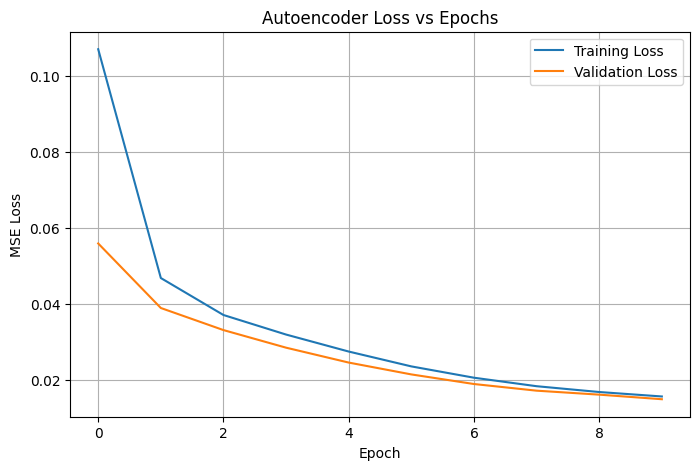

In [ ]:
# 9. Plot loss
# --------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Autoencoder Loss vs Epochs")
plt.legend()
plt.grid()
plt.show()

In [ ]:
# 10. Reconstruct test images
# --------------------------------------------------

x_test_reconstructed = autoencoder.predict(x_test)




313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


In [ ]:
# --------------------------------------------------
# 11. Calculate reconstruction error
# --------------------------------------------------

reconstruction_error = np.mean(
    np.square(x_test - x_test_reconstructed),
    axis=1
)



In [ ]:

# --------------------------------------------------
# 12. Calculate threshold using normal data
# --------------------------------------------------

normal_reconstructed = autoencoder.predict(x_train_normal)

normal_error = np.mean(
    np.square(x_train_normal - normal_reconstructed),
    axis=1
)

threshold = np.percentile(normal_error, 95)

print("Anomaly Threshold:", threshold)




186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
Anomaly Threshold: 0.028596679


In [ ]:
# --------------------------------------------------
# 13. Detect anomalies
# --------------------------------------------------

anomalies = reconstruction_error > threshold

print("Total test samples:", len(x_test))
print("Detected anomalies:", np.sum(anomalies))
print("Detected normal samples:", np.sum(~anomalies))




Total test samples: 10000
Detected anomalies: 8955
Detected normal samples: 1045


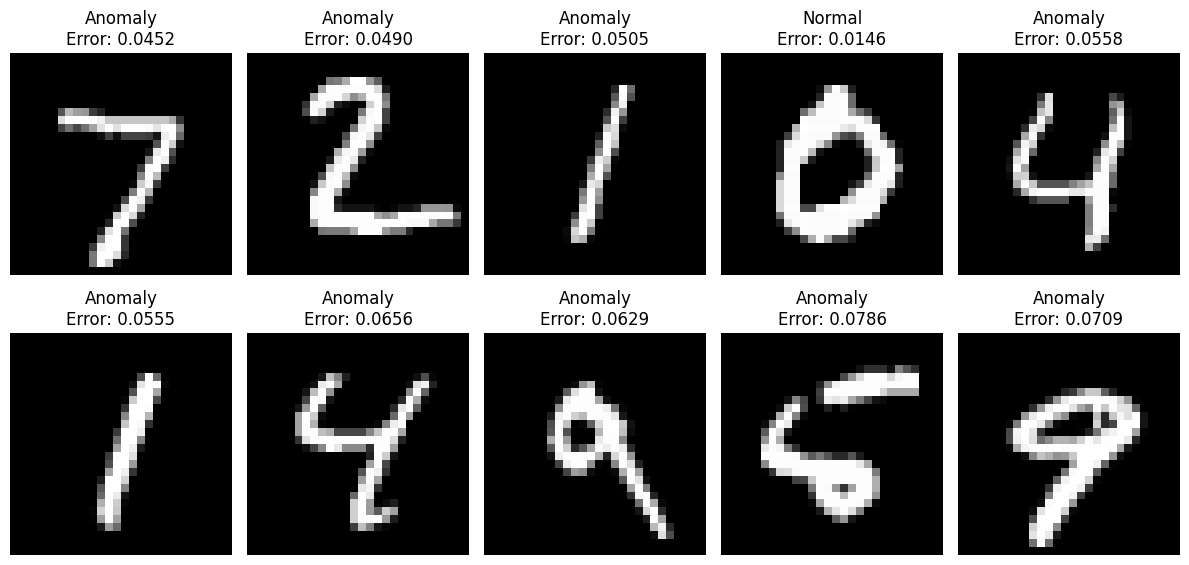

In [ ]:
# --------------------------------------------------
# 14. Display images
# --------------------------------------------------

plt.figure(figsize=(12, 6))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")

    status = "Anomaly" if anomalies[i] else "Normal"

    plt.title(
        f"{status}\nError: {reconstruction_error[i]:.4f}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()




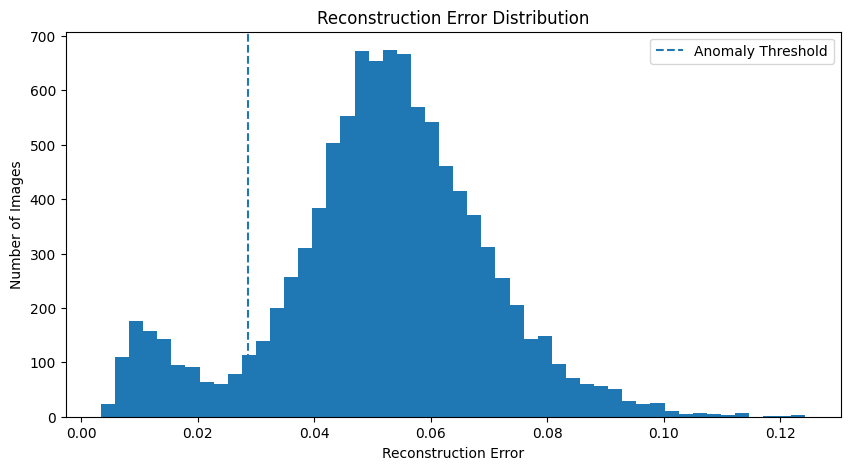

In [ ]:
# --------------------------------------------------
# 15. Reconstruction error distribution
# --------------------------------------------------

plt.figure(figsize=(10, 5))

plt.hist(reconstruction_error, bins=50)

plt.axvline(
    threshold,
    linestyle="--",
    label="Anomaly Threshold"
)

plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Images")
plt.title("Reconstruction Error Distribution")
plt.legend()

plt.show()